<a href="https://colab.research.google.com/github/MothDB03/Modern-Tools-Final-Project/blob/main/Final_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#import things
import pandas as pd
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
#raw data importing
#US population
US_path = Path('/content/drive/MyDrive/Colab Notebooks/insy/us_annual_population_1900_2026.csv')
#US_df = pd.read_csv(US_path, parse_dates=['observation_date'])

modern_path = Path('/content/drive/MyDrive/Colab Notebooks/Final Project/Data/National Parks Attendence 1979 - present.csv')
modern_df = pd.read_csv(modern_path, dtype=str)

old_path = Path('/content/drive/MyDrive/Colab Notebooks/Final Project/Data/National park Recreation Visits (1904 - 1979).csv')
old_df = pd.read_csv(old_path)

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Colab Notebooks/Final Project/Data/National Parks Attendence 1979 - present.csv'

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#data formatting
#Modern Data
# --- 1. Text and Geographic Identifier Columns ---
modern_df['ParkName'] = modern_df['ParkName'].astype('string')
modern_df['UnitCode'] = modern_df['UnitCode'].astype('string')
modern_df['ParkType'] = modern_df['ParkType'].astype('string')
modern_df['Region'] = modern_df['Region'].astype('string')
modern_df['State'] = modern_df['State'].astype('string')

# --- 2. Temporal Fields ---
modern_df['Year'] = modern_df['Year'].str.replace(',', '', regex=False).astype('Int64')
modern_df['Month'] = modern_df['Month'].str.replace(',', '', regex=False).astype('Int64')

# --- 3. Monthly Visitation and Hours Metrics ---
modern_df['RecreationVisits'] = modern_df['RecreationVisits'].str.replace(',', '', regex=False).astype('Int64')
modern_df['NonRecreationVisits'] = modern_df['NonRecreationVisits'].str.replace(',', '', regex=False).astype('Int64')
modern_df['RecreationHours'] = modern_df['RecreationHours'].str.replace(',', '', regex=False).astype('Int64')
modern_df['NonRecreationHours'] = modern_df['NonRecreationHours'].str.replace(',', '', regex=False).astype('Int64')

# --- 4. Overnight Stay Categories ---
modern_df['ConcessionerLodging'] = modern_df['ConcessionerLodging'].str.replace(',', '', regex=False).astype('Int64')
modern_df['ConcessionerCamping'] = modern_df['ConcessionerCamping'].str.replace(',', '', regex=False).astype('Int64')
modern_df['TentCampers'] = modern_df['TentCampers'].str.replace(',', '', regex=False).astype('Int64')
modern_df['RVCampers'] = modern_df['RVCampers'].str.replace(',', '', regex=False).astype('Int64')
modern_df['Backcountry'] = modern_df['Backcountry'].str.replace(',', '', regex=False).astype('Int64')
modern_df['NonRecreationOvernightStays'] = modern_df['NonRecreationOvernightStays'].str.replace(',', '', regex=False).astype('Int64')
modern_df['MiscellaneousOvernightStays'] = modern_df['MiscellaneousOvernightStays'].str.replace(',', '', regex=False).astype('Int64')

# --- 5. Total Descriptive and Summary Metrics ---
modern_df['ParkNameTotal'] = modern_df['ParkNameTotal'].astype('string')
modern_df['UnitCodeTotal'] = modern_df['UnitCodeTotal'].astype('string')
modern_df['ParkTypeTotal'] = modern_df['ParkTypeTotal'].astype('string')
modern_df['RegionTotal'] = modern_df['RegionTotal'].astype('string')
modern_df['StateTotal'] = modern_df['StateTotal'].astype('string')
modern_df['YearTotal'] = modern_df['YearTotal'].str.replace(',', '', regex=False).astype('Int64')
modern_df['RecreationVisitsTotal'] = modern_df['RecreationVisitsTotal'].str.replace(',', '', regex=False).astype('Int64')
modern_df['NonRecreationVisitsTotal'] = modern_df['NonRecreationVisitsTotal'].str.replace(',', '', regex=False).astype('Int64')
modern_df['RecreationHoursTotal'] = modern_df['RecreationHoursTotal'].str.replace(',', '', regex=False).astype('Int64')
modern_df['NonRecreationHoursTotal'] = modern_df['NonRecreationHoursTotal'].str.replace(',', '', regex=False).astype('Int64')
modern_df['ConcessionerLodgingTotal'] = modern_df['ConcessionerLodgingTotal'].str.replace(',', '', regex=False).astype('Int64')
modern_df['ConcessionerCampingTotal'] = modern_df['ConcessionerCampingTotal'].str.replace(',', '', regex=False).astype('Int64')
modern_df['TentCampersTotal'] = modern_df['TentCampersTotal'].str.replace(',', '', regex=False).astype('Int64')
modern_df['RVCampersTotal'] = modern_df['RVCampersTotal'].str.replace(',', '', regex=False).astype('Int64')
modern_df['BackcountryTotal'] = modern_df['BackcountryTotal'].str.replace(',', '', regex=False).astype('Int64')
modern_df['NonRecreationOvernightStaysTotal'] = modern_df['NonRecreationOvernightStaysTotal'].str.replace(',', '', regex=False).astype('Int64')
modern_df['MiscellaneousOvernightStaysTotal'] = modern_df['MiscellaneousOvernightStaysTotal'].str.replace(',', '', regex=False).astype('Int64')

# Clean ParkName Column
modern_df['ParkName'] = modern_df['ParkName'].str.replace(r' NP & PRES| NP', '', regex=True)

In [ ]:
modern_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35471 entries, 0 to 35470
Data columns (total 35 columns):
 #   Column                            Non-Null Count  Dtype 
---  ------                            --------------  ----- 
 0   ParkName                          35471 non-null  string
 1   UnitCode                          35471 non-null  string
 2   ParkType                          35471 non-null  string
 3   Region                            35471 non-null  string
 4   State                             35471 non-null  string
 5   Year                              35471 non-null  Int64 
 6   Month                             35471 non-null  Int64 
 7   RecreationVisits                  35471 non-null  Int64 
 8   NonRecreationVisits               35471 non-null  Int64 
 9   RecreationHours                   35471 non-null  Int64 
 10  NonRecreationHours                35471 non-null  Int64 
 11  ConcessionerLodging               35471 non-null  Int64 
 12  ConcessionerCampin

In [ ]:
old_df['Total'] = old_df['Total'].str.replace(',', '', regex=False).astype('Int64')
old_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2651 entries, 0 to 2650
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   ParkName  2651 non-null   object
 1   UnitCode  2651 non-null   object
 2   ParkType  2651 non-null   object
 3   Region    2651 non-null   object
 4   State     2651 non-null   object
 5   Year      2651 non-null   int64 
 6   Total     2651 non-null   Int64 
dtypes: Int64(1), int64(1), object(5)
memory usage: 147.7+ KB


In [ ]:
US_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 66 entries, 0 to 65
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   observation_date  66 non-null     datetime64[ns]
 1   POPTOTUSA647NWDB  66 non-null     int64         
dtypes: datetime64[ns](1), int64(1)
memory usage: 1.2 KB


#Data Cleaning and Combination

In [ ]:
#Adjust 1979-now so it can merge with 1904-1978
post_1979_annual = modern_df.groupby(
    ['ParkName','Year', 'UnitCode','ParkType','Region','State'], as_index = False
    ).agg(Total=('RecreationVisits', 'sum')
)

post79grouped = modern_df.groupby(
    ['ParkName', 'Year', 'UnitCode','ParkType','Region','State'],
    as_index = False)[['RecreationVisits','NonRecreationVisits','ConcessionerLodging',
                       'ConcessionerCamping','TentCampers',
                       'RVCampers','Backcountry'
]].sum()
columns_to_sum = ['RecreationVisits','NonRecreationVisits','ConcessionerLodging',
                  'ConcessionerCamping','TentCampers','RVCampers','Backcountry']
post79grouped['Total'] = post79grouped[columns_to_sum].sum(axis=1)

post79grouped = post79grouped.drop(columns = ['RecreationVisits','NonRecreationVisits','ConcessionerLodging','ConcessionerCamping','TentCampers', 'RVCampers','Backcountry'])

#post_1979_annual

#merge data
full_yearly = pd.concat([old_df,post79grouped],ignore_index = True
                        ).drop(columns = ['ParkType'])
full_yearly.groupby(['Year']).sum().drop(columns = ['ParkName','UnitCode','Region','State'])



,Total
Year,
1904,134417
1905,167142
1906,47751
1907,49349
1908,62310
...,...
2021,122855328
2022,121707209
2023,125736531


In [ ]:
post79grouped

,ParkName,Year,UnitCode,ParkType,Region,State,Total
0,Acadia NP,1979,ACAD,National Park,Northeast,ME,3183279
1,Acadia NP,1980,ACAD,National Park,Northeast,ME,3273095
2,Acadia NP,1981,ACAD,National Park,Northeast,ME,3402973
3,Acadia NP,1982,ACAD,National Park,Northeast,ME,3755161
4,Acadia NP,1983,ACAD,National Park,Northeast,ME,4307663
...,...,...,...,...,...,...,...
2951,Zion NP,2021,ZION,National Park,Intermountain,UT,5061735
2952,Zion NP,2022,ZION,National Park,Intermountain,UT,4714317
2953,Zion NP,2023,ZION,National Park,Intermountain,UT,4645138
2954,Zion NP,2024,ZION,National Park,Intermountain,UT,4968492


In [ ]:
def remove_negative_counts(df):
    """
    Scans all numeric columns in a DataFrame and replaces any negative
    values (legacy placeholder codes) with pandas missing values (NA).
    """
    # Identify all columns that contain numeric data types
    numeric_cols = df.select_dtypes(include=['number', 'Int64']).columns

    # Apply a blanket condition: where values are less than 0, replace with NA
    df[numeric_cols] = df[numeric_cols].mask(df[numeric_cols] < 0, pd.NA)

    return df

In [ ]:
temp_df = remove_negative_counts(modern_df)
cleaned_17tonow = temp_df.drop(columns = [
    'ParkNameTotal','UnitCodeTotal','ParkTypeTotal',
    'RegionTotal','StateTotal','YearTotal',
    'RecreationVisitsTotal','NonRecreationVisitsTotal',
    'RecreationHoursTotal','NonRecreationHoursTotal',
    'ConcessionerLodgingTotal','ConcessionerCampingTotal',
    'TentCampersTotal','RVCampersTotal',
    'BackcountryTotal','NonRecreationOvernightStaysTotal',
    'MiscellaneousOvernightStaysTotal'])

In [ ]:
modern_df.head()

,ParkName,UnitCode,ParkType,Region,State,Year,Month,RecreationVisits,NonRecreationVisits,RecreationHours,...,NonRecreationVisitsTotal,RecreationHoursTotal,NonRecreationHoursTotal,ConcessionerLodgingTotal,ConcessionerCampingTotal,TentCampersTotal,RVCampersTotal,BackcountryTotal,NonRecreationOvernightStaysTotal,MiscellaneousOvernightStaysTotal
0,Arches NP,ARCH,National Park,Intermountain,UT,1979,1,2970,0,10998,...,0,1825420,0,0,0,18772,17605,2332,0,3759
1,Arches NP,ARCH,National Park,Intermountain,UT,1979,2,3135,0,15573,...,0,1825420,0,0,0,18772,17605,2332,0,3759
2,Arches NP,ARCH,National Park,Intermountain,UT,1979,3,14659,0,104265,...,0,1825420,0,0,0,18772,17605,2332,0,3759
3,Arches NP,ARCH,National Park,Intermountain,UT,1979,4,31818,0,224598,...,0,1825420,0,0,0,18772,17605,2332,0,3759
4,Arches NP,ARCH,National Park,Intermountain,UT,1979,5,39266,0,299310,...,0,1825420,0,0,0,18772,17605,2332,0,3759


#Exporting Cleaned Data

In [ ]:
export_path = Path('/content/drive/MyDrive/Colab Notebooks/Final Project/Data/full_yearly')
full_yearly.to_csv(export_path, index=False)

In [ ]:
export_path = Path('/content/drive/MyDrive/Colab Notebooks/Final Project/Data/1979-Now Cleaned Columns')
cleaned_17tonow.to_csv(export_path, index=False)

In [ ]:
cleaned_17tonow

,ParkName,UnitCode,ParkType,Region,State,Year,Month,RecreationVisits,NonRecreationVisits,RecreationHours,NonRecreationHours,ConcessionerLodging,ConcessionerCamping,TentCampers,RVCampers,Backcountry,NonRecreationOvernightStays,MiscellaneousOvernightStays
0,Arches NP,ARCH,National Park,Intermountain,UT,1979,1,2970,0,10998,0,0,0,35,47,5,0,0
1,Arches NP,ARCH,National Park,Intermountain,UT,1979,2,3135,0,15573,0,0,0,108,120,29,0,0
2,Arches NP,ARCH,National Park,Intermountain,UT,1979,3,14659,0,104265,0,0,0,1143,1115,254,0,0
3,Arches NP,ARCH,National Park,Intermountain,UT,1979,4,31818,0,224598,0,0,0,2152,2342,401,0,486
4,Arches NP,ARCH,National Park,Intermountain,UT,1979,5,39266,0,299310,0,0,0,2380,3112,927,0,1144
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35466,Yosemite NP,YOSE,National Park,Pacific West,CA,2025,8,594060,23068,10314980,23068,81299,0,98407,43412,35976,0,3216
35467,Yosemite NP,YOSE,National Park,Pacific West,CA,2025,9,487733,18937,8868863,18937,100890,0,64459,41224,18998,0,4079
35468,Yosemite NP,YOSE,National Park,Pacific West,CA,2025,10,445779,17479,6022224,17479,51859,0,42012,31516,8493,0,1596
35469,Yosemite NP,YOSE,National Park,Pacific West,CA,2025,11,234709,9871,2631728,9871,35884,0,8813,6640,327,0,414


#IMPORTING CLEAN DATA

In [49]:
#import things
import pandas as pd
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from sklearn.metrics import r2_score
import seaborn as sns

In [50]:
#paths for Tim
#You will need to reference your own pathes so this works right
modern_cleaned_path = Path('/content/drive/MyDrive/Colab Notebooks/Final Project/Data/1979-Now Cleaned Columns')
yearly_path = Path('/content/drive/MyDrive/Colab Notebooks/Final Project/Data/full_yearly')
US_path = Path('/content/drive/MyDrive/Colab Notebooks/Final Project/Data/us_annual_population_1900_2026.csv')

In [16]:
#paths for Ethan
#You will need to reference your own pathes so this works right
modern_cleaned_path = Path('/content/drive/MyDrive/Colab Notebooks/Final Project/Data/1979-Now Cleaned Columns')
yearly_path = Path('/content/drive/MyDrive/Colab Notebooks/Final Project/Data/full_yearly')
US_path = Path('/content/drive/MyDrive/Colab Notebooks/Final Project/Data/us_annual_population_1900_2026.csv')

In [18]:
#Define data frame
modern_data = pd.read_csv(modern_cleaned_path)
yearly_df = pd.read_csv(yearly_path)
US_df = pd.read_csv(US_path)

In [14]:
full_year = yearly_df.groupby('Year')['Total'].sum()
simple_us = US_df.rename(columns = {'US_Resident_Population':'Population'}).set_index('Year')


#Analysis

###Visitation as percent of population

In [15]:
popWithYear = pd.merge(full_year, simple_us, left_index=True,right_index=True,)
popWithYear['Percent'] = popWithYear['Total']/popWithYear['Population']

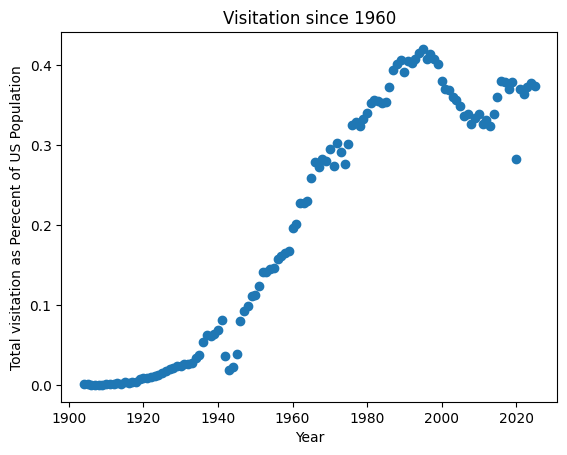

In [ ]:
plt.scatter(popWithYear.index,popWithYear['Percent'])
plt.xlabel('Year')
plt.ylabel('Total visitation as Perecent of US Population')
plt.title('Visitation since 1960')
plt.show()

Training R²: 0.987532


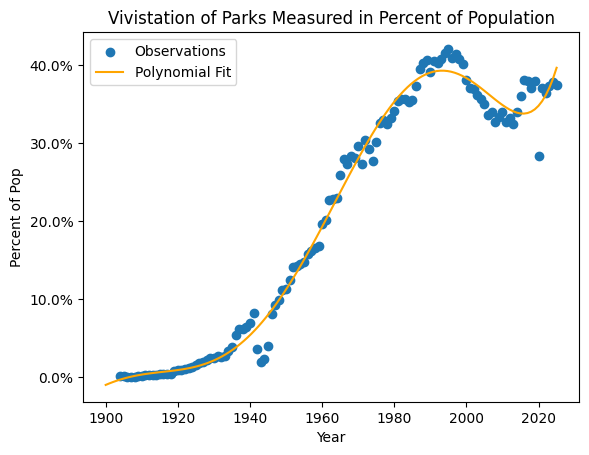

In [16]:
#Graph 1
model1 = np.poly1d(np.polyfit(popWithYear.index, popWithYear['Percent'], deg=6))
grid1 = np.linspace(1900, 2025, 125)
#print(model)
plt.scatter(popWithYear.index, popWithYear['Percent'], label='Observations')
plt.plot(grid1, model1(grid1), color='orange', label='Polynomial Fit')
plt.xlabel('Year')
plt.ylabel('Percent of Pop')
plt.legend()
plt.title('Vivistation of Parks Measured in Percent of Population')
plt.gca().yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
score = r2_score(popWithYear['Percent'], model1(popWithYear.index))
print(f'Training R²: {score:.6f}')

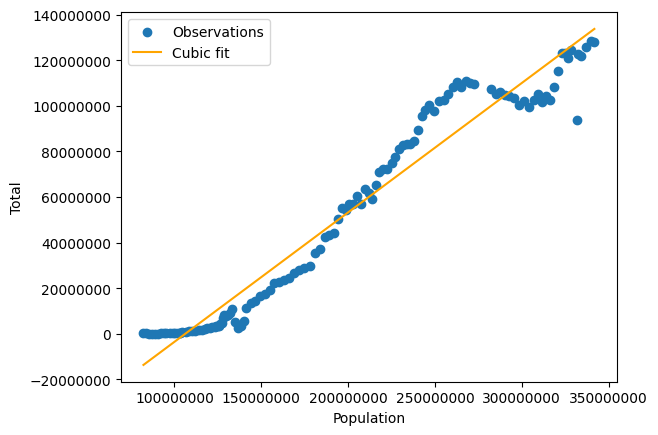

In [ ]:
#Graph 2
model2 = np.poly1d(np.polyfit(popWithYear['Population'], popWithYear['Total'], deg=1))
grid2 = np.linspace(popWithYear['Population'].min(), popWithYear['Population'].max() , 5)
plt.scatter(popWithYear['Population'], popWithYear['Total'], label='Observations')
plt.plot(grid2, model2(grid2), color='orange', label='Cubic fit')
plt.xlabel('Population')
plt.ylabel('Total')
plt.legend()
plt.ticklabel_format(style='plain', axis='both')

In [ ]:
print(f'Since the NPS started recording data in 1904 they have had a total of {yearly_df['Total'].sum(axis=0):,} visitors')

Since the NPS started recording data in 1904 they have had a total of 6,367,903,055 visitors


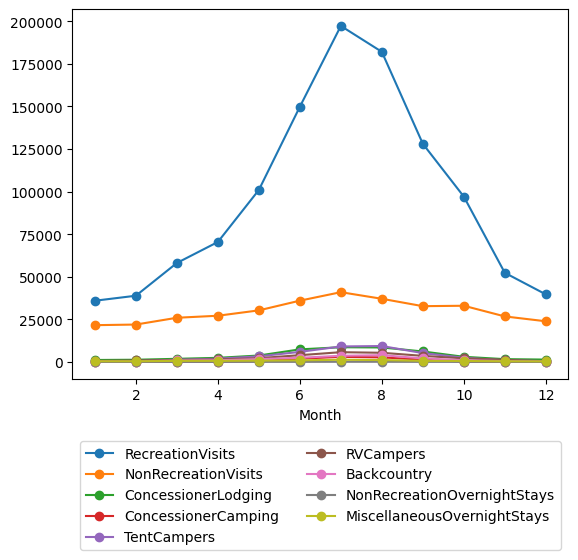

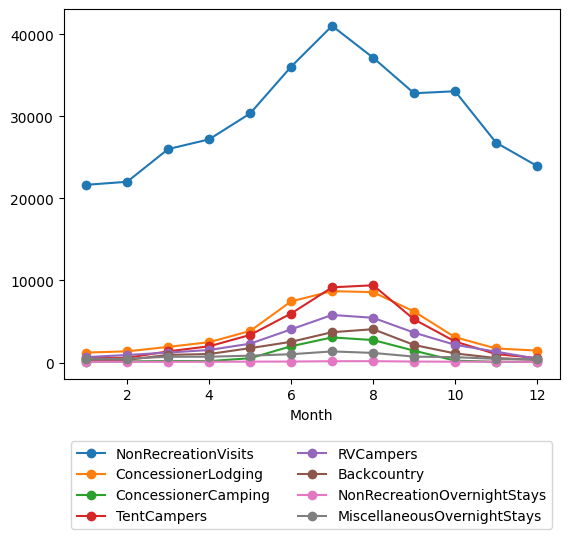

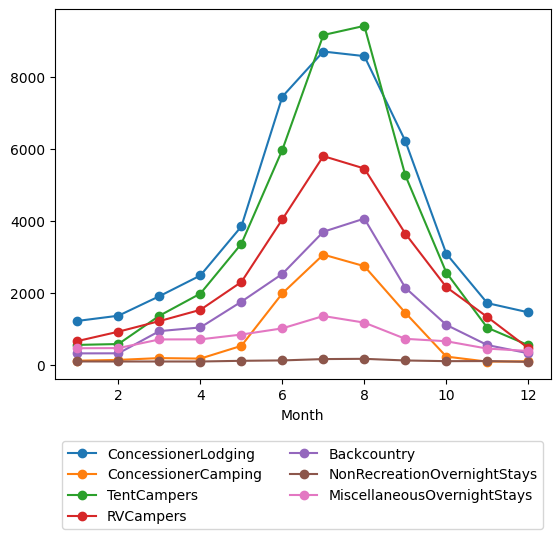

In [17]:
#Graph based on type of visitor based on month
monthlyAvg = modern_data.groupby('Month')[[
    'RecreationVisits', 'NonRecreationVisits','ConcessionerLodging',
    'ConcessionerCamping','TentCampers','RVCampers','Backcountry',
    'NonRecreationOvernightStays','MiscellaneousOvernightStays']].mean()
ax = monthlyAvg.plot(kind='line', marker='o')
ax.legend(bbox_to_anchor=(0.5, -0.15), loc='upper center', ncol=2)
monthlyAvgNoRec = modern_data.groupby('Month')[[
    'NonRecreationVisits','ConcessionerLodging',
    'ConcessionerCamping','TentCampers','RVCampers','Backcountry',
    'NonRecreationOvernightStays','MiscellaneousOvernightStays']].mean()
ax = monthlyAvgNoRec.plot(kind='line', marker='o')
ax.legend(bbox_to_anchor=(0.5, -0.15), loc='upper center', ncol=2)
monthlyAvgThin = modern_data.groupby('Month')[[
    'ConcessionerLodging',
    'ConcessionerCamping','TentCampers','RVCampers','Backcountry',
    'NonRecreationOvernightStays','MiscellaneousOvernightStays']].mean()
ax = monthlyAvgThin.plot(kind='line', marker='o')
ax.legend(bbox_to_anchor=(0.5, -0.15), loc='upper center', ncol=2)

/tmp/ipykernel_1683/4036775557.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=regionAvg, x='Region', y='Total', palette='tab10')
/tmp/ipykernel_1683/4036775557.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data = regionAvg, x = 'Region', y = 'Total',estimator='mean', palette = 'tab10')


Text(0.5, 1.0, 'All Time Total Visitation by Region')

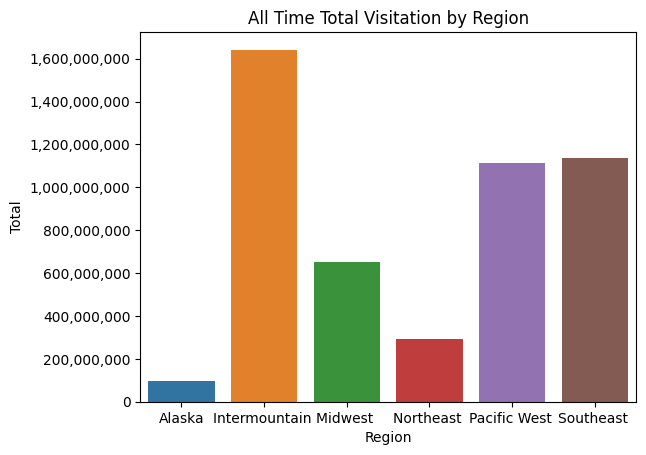

In [29]:
#Based on region sum
regionAvg = modern_data.groupby('Region')[[
    'RecreationVisits','NonRecreationVisits','ConcessionerLodging',
    'ConcessionerCamping','TentCampers','RVCampers','Backcountry',
    'NonRecreationOvernightStays','MiscellaneousOvernightStays']].sum().round().astype(int)

columnsToSum = ['RecreationVisits','NonRecreationVisits','ConcessionerLodging',
                'ConcessionerCamping','TentCampers','RVCampers','Backcountry',
    'NonRecreationOvernightStays','MiscellaneousOvernightStays']

regionAvg['Total'] = regionAvg[columnsToSum].sum(axis=1)
ax = sns.barplot(data=regionAvg, x='Region', y='Total', palette='tab10')
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))
sns.barplot(data = regionAvg, x = 'Region', y = 'Total',estimator='mean', palette = 'tab10')
plt.title('All Time Total Visitation by Region')
#regionAvg

/tmp/ipykernel_1683/787848027.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=regionAvg, x='Region', y='Total', palette='tab10')
/tmp/ipykernel_1683/787848027.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data = regionAvg, x = 'Region', y = 'Total',estimator='mean', palette = 'tab10')


Text(0.5, 1.0, "Average Visitation of a Region's Park per Month")

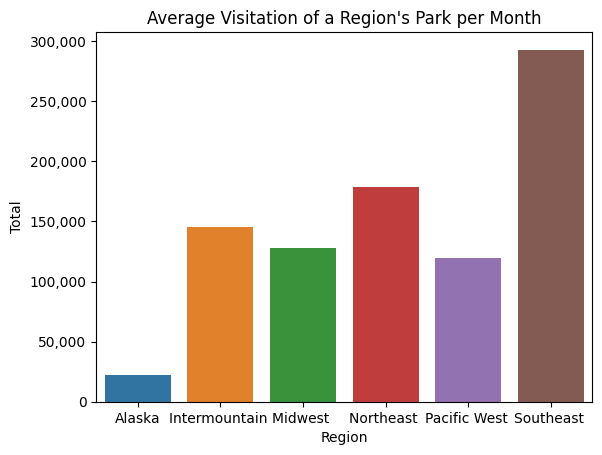

In [28]:
#Based on region Mean
regionAvg = modern_data.groupby('Region')[[
    'RecreationVisits','NonRecreationVisits','ConcessionerLodging',
    'ConcessionerCamping','TentCampers','RVCampers','Backcountry',
    'NonRecreationOvernightStays','MiscellaneousOvernightStays']].mean().round().astype(int)

columnsToSum = ['RecreationVisits','NonRecreationVisits','ConcessionerLodging',
                'ConcessionerCamping','TentCampers','RVCampers','Backcountry',
    'NonRecreationOvernightStays','MiscellaneousOvernightStays']

regionAvg['Total'] = regionAvg[columnsToSum].sum(axis=1)
ax = sns.barplot(data=regionAvg, x='Region', y='Total', palette='tab10')
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))
sns.barplot(data = regionAvg, x = 'Region', y = 'Total',estimator='mean', palette = 'tab10')
plt.title("Average Visitation of a Region's Park per Month")
#regionAvg

/tmp/ipykernel_1683/3598251929.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=batch_df, x='ParkName', y='Total', palette='tab10')


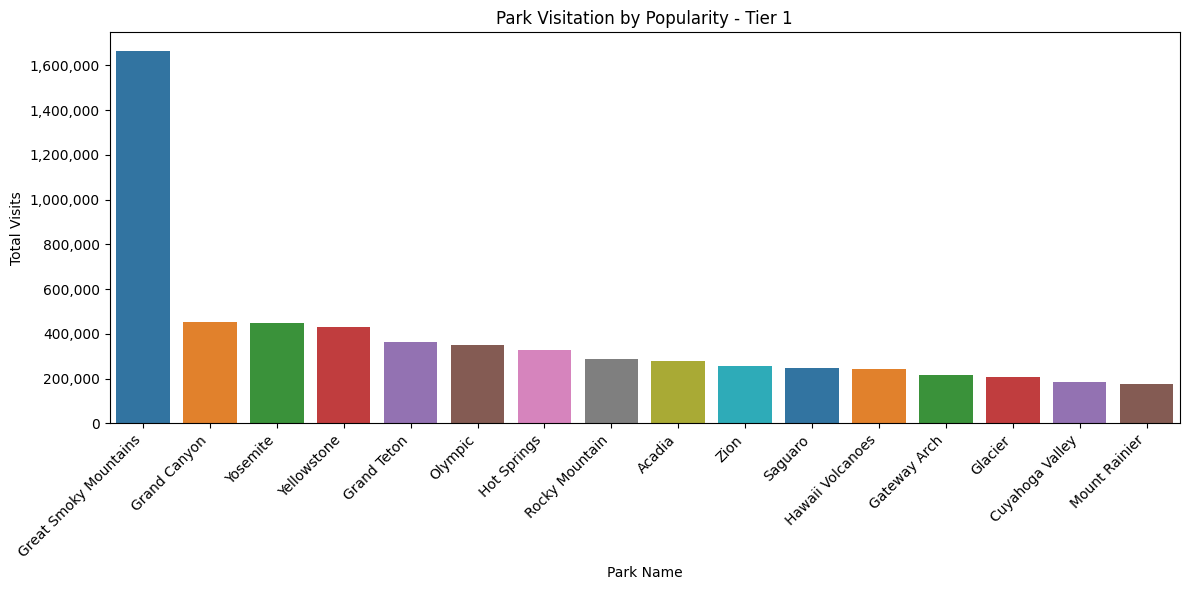

/tmp/ipykernel_1683/3598251929.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=batch_df, x='ParkName', y='Total', palette='tab10')


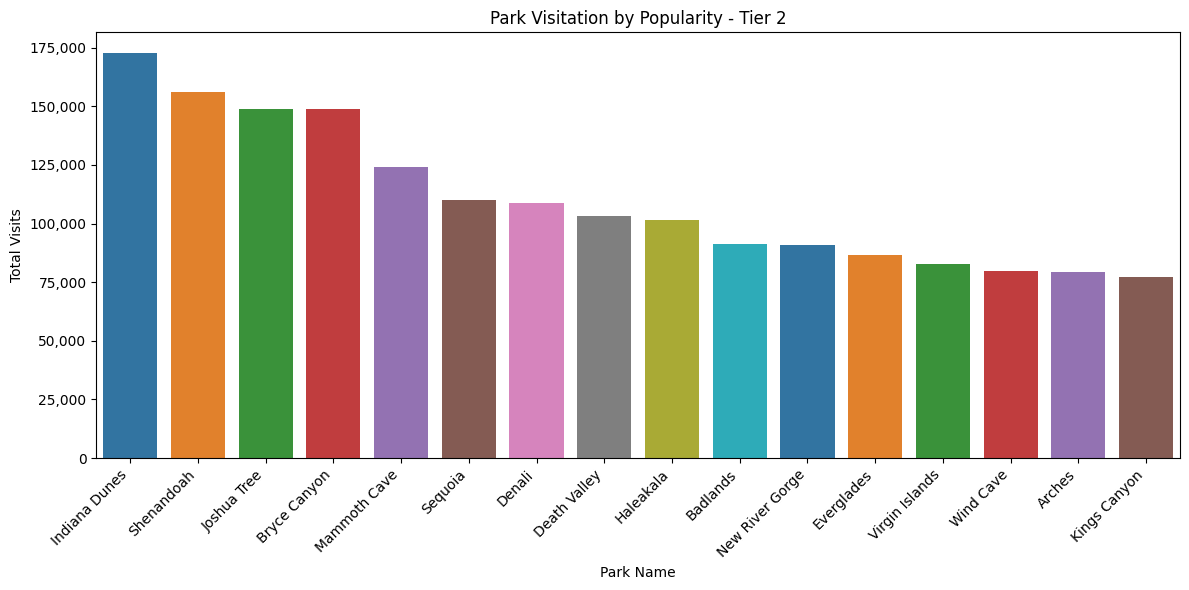

/tmp/ipykernel_1683/3598251929.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=batch_df, x='ParkName', y='Total', palette='tab10')


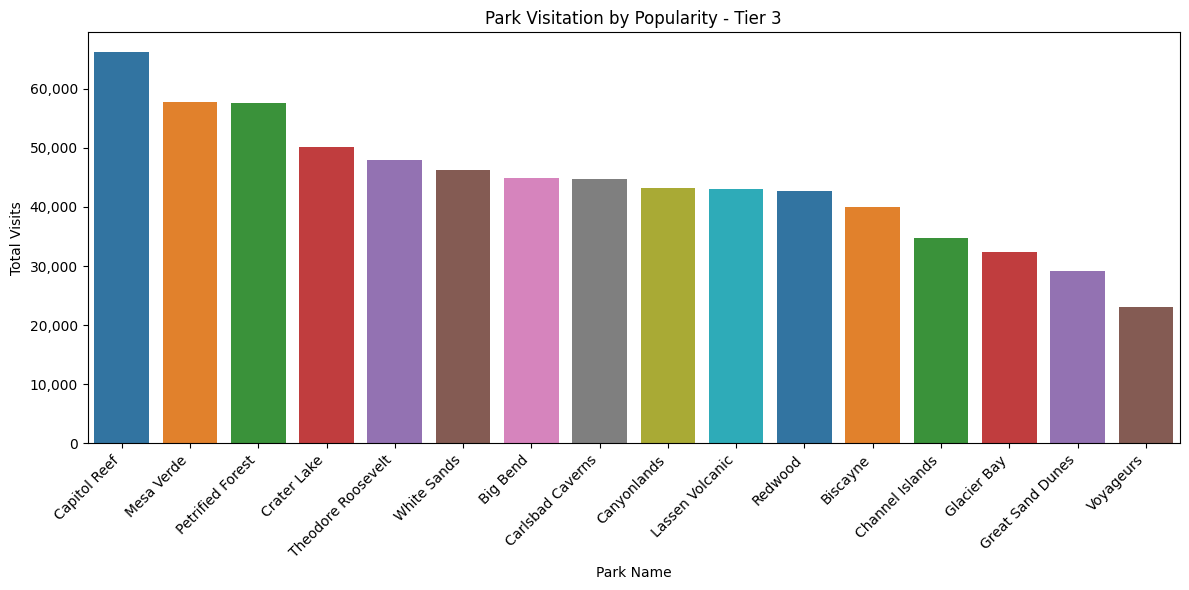

/tmp/ipykernel_1683/3598251929.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=batch_df, x='ParkName', y='Total', palette='tab10')


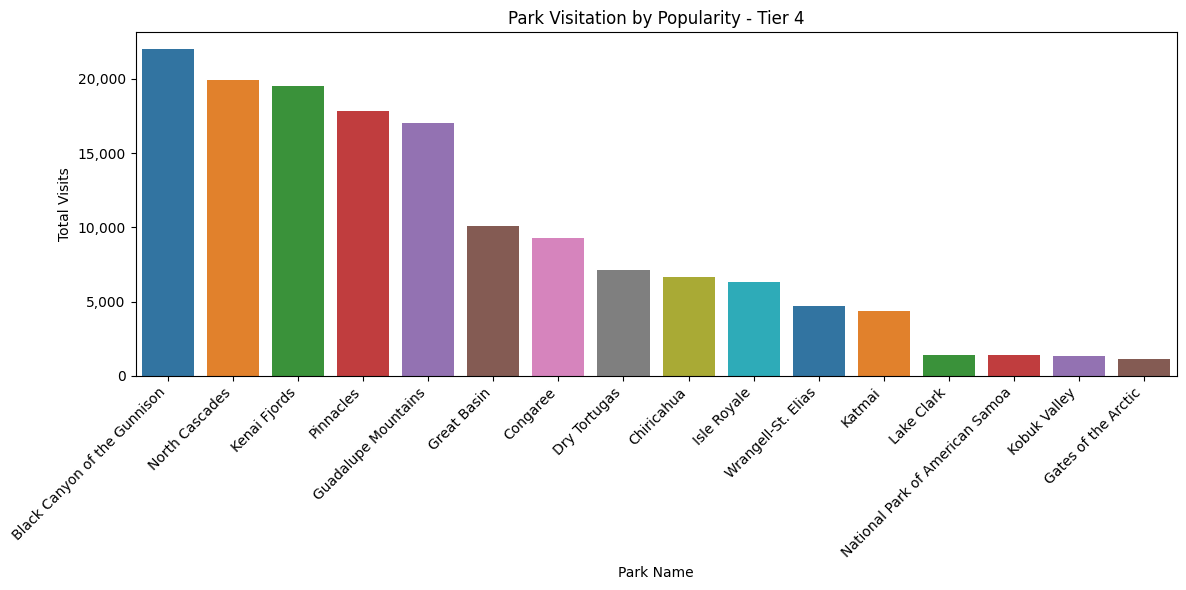

,State,Region,RecreationVisits,NonRecreationVisits,ConcessionerLodging,ConcessionerCamping,TentCampers,RVCampers,Backcountry,NonRecreationOvernightStays,MiscellaneousOvernightStays,Total
ParkName,,,,,,,,,,,,
Congaree,SC,Southeast,8971,0,0,0,59,0,47,0,234,9311
Dry Tortugas,FL,Southeast,4073,534,0,0,521,0,0,662,1319,7109
Chiricahua,AZ,Intermountain,5404,218,0,0,437,497,0,0,77,6633
Isle Royale,MI,Midwest,1708,21,651,63,562,0,2827,63,412,6307
Wrangell-St. Elias,AK,Alaska,4224,48,6,1,0,0,218,12,178,4687
Katmai,AK,Alaska,3336,95,309,0,222,0,359,34,8,4363
Lake Clark,AK,Alaska,975,122,0,0,0,0,263,41,2,1403
National Park of American Samoa,AS,Pacific West,1382,0,0,0,0,0,0,0,0,1382
Kobuk Valley,AK,Alaska,540,448,0,0,0,0,162,183,0,1333


In [47]:
#Park and Popularity
parkAvg = modern_data.groupby(['ParkName','Region','State'])[[
    'RecreationVisits','NonRecreationVisits','ConcessionerLodging',
    'ConcessionerCamping','TentCampers','RVCampers','Backcountry',
    'NonRecreationOvernightStays','MiscellaneousOvernightStays']].mean().round().astype(int).reset_index('Region').reset_index('State')

columnsToSum = ['RecreationVisits','NonRecreationVisits','ConcessionerLodging',
                'ConcessionerCamping','TentCampers','RVCampers','Backcountry',
    'NonRecreationOvernightStays','MiscellaneousOvernightStays']

parkAvg['Total'] = parkAvg[columnsToSum].sum(axis=1)
parkAvgSorted = parkAvg.sort_values(by = 'Total', ascending = False)

batch_size = 16
num_batches = len(parkAvgSorted) // batch_size + (1 if len(parkAvgSorted) % batch_size > 0 else 0)
for i in range(num_batches):
    start_idx = i * batch_size
    end_idx = start_idx + batch_size
    batch_df = parkAvgSorted.iloc[start_idx:end_idx]

    plt.figure(figsize=(12, 6))
    ax = sns.barplot(data=batch_df, x='ParkName', y='Total', palette='tab10')

    # 1. Explicitly turn off scientific notation and offsets
    formatter = mtick.ScalarFormatter(useOffset=False)
    formatter.set_scientific(False)
    #ax.yaxis.set_major_formatter(formatter)
    # Alternatively, force a fixed-point string format with commas
    ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))
    plt.xticks(rotation=45, ha='right')
    plt.title(f'Park Visitation by Popularity - Tier {i+1}')
    plt.xlabel('Park Name')
    plt.ylabel('Total Visits')
    plt.tight_layout()
    plt.show()

parkAvgSorted.tail(10)

In [48]:
parkAvg['Region'].value_counts()

,count
Region,
Intermountain,20
Pacific West,17
Midwest,9
Alaska,8
Southeast,7
Northeast,3


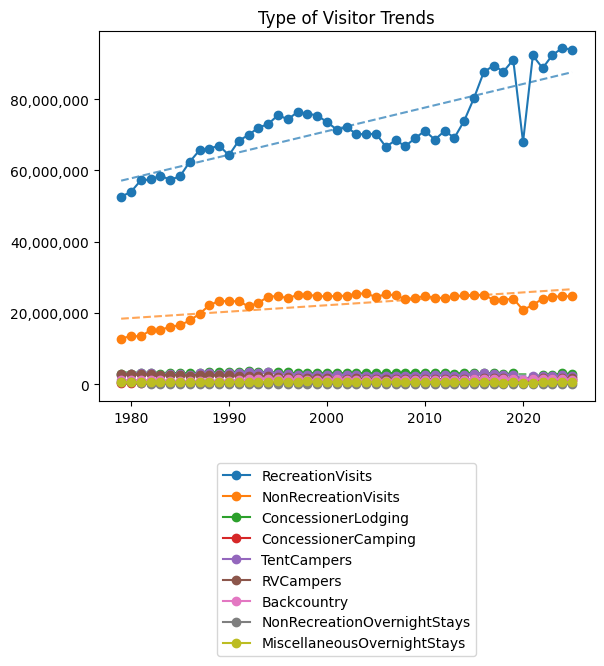

In [46]:
# Year and type
yearType = modern_data.groupby(['Year'])[
    [
        'RecreationVisits',
        'NonRecreationVisits',
        'ConcessionerLodging',
        'ConcessionerCamping',
        'TentCampers',
        'RVCampers',
        'Backcountry',
        'NonRecreationOvernightStays',
        'MiscellaneousOvernightStays',
    ]
].sum().astype(int)

yearTypeThin = yearType#.drop(columns=['RecreationVisits', 'NonRecreationVisits'])

colors = plt.cm.tab10.colors

for idx, col in enumerate(yearTypeThin.columns):
    series_color = colors[idx % len(colors)]

    # 1. Plot the original annual data points and line with a distinct color
    plt.plot(
        yearTypeThin.index,
        yearTypeThin[col],
        marker='o',
        color=series_color,
        label=col,
    )

    # 2. Calculate linear line of best fit (degree 1) using the Year index
    z = np.polyfit(yearTypeThin.index, yearTypeThin[col], 1)
    p = np.poly1d(z)

    # 3. Overlay the dashed trend line in the matching series color
    plt.plot(
        yearTypeThin.index,
        p(yearTypeThin.index),
        linestyle='--',
        color=series_color,
        alpha=0.7,
    )

plt.title("Type of Visitor Trends")
plt.gca().yaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.legend(bbox_to_anchor=(0.5, -0.15), loc='upper center')
plt.show()

/tmp/ipykernel_1683/2485274019.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data = byState, x = 'State', y = 'Total',estimator='mean', palette = 'tab10')


<Axes: title={'center': 'Average Visitation per State per Year'}, xlabel='State', ylabel='Total'>

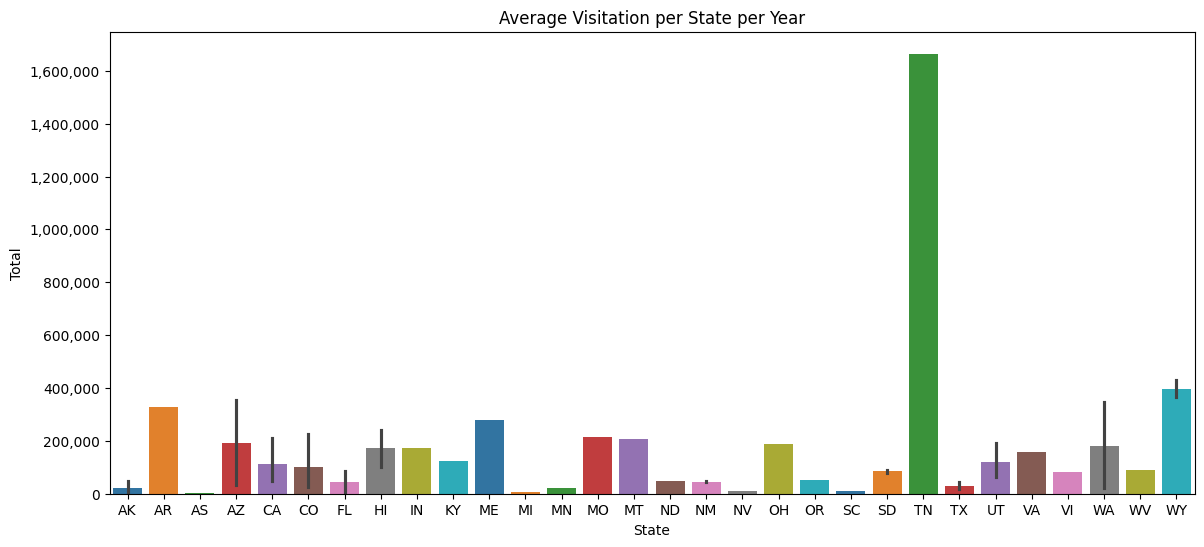

In [23]:
#PopularityByStates
byState = modern_data.groupby(['State', 'ParkName'])[['RecreationVisits','NonRecreationVisits','ConcessionerLodging',
    'ConcessionerCamping','TentCampers','RVCampers','Backcountry',
    'NonRecreationOvernightStays','MiscellaneousOvernightStays']].mean().round().astype(int)
columnsToSum = ['RecreationVisits','NonRecreationVisits','ConcessionerLodging',
    'ConcessionerCamping','TentCampers','RVCampers','Backcountry',
    'NonRecreationOvernightStays','MiscellaneousOvernightStays']
byState['Total'] = byState[columnsToSum].sum(axis = 1)
byState.sort_values(by = 'Total', ascending = False)

plt.figure(figsize=(14, 6))
plt.gca().yaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))
plt.title('Average Visitation per State per Year')
sns.barplot(data = byState, x = 'State', y = 'Total',estimator='mean', palette = 'tab10')

/tmp/ipykernel_7294/2447878084.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  smokeyMountains['Total'] = smokeyMountains[columnsToSum].sum(axis = 1)
/tmp/ipykernel_7294/2447878084.py:7: RankWarning: Polyfit may be poorly conditioned
  model1 = np.poly1d(np.polyfit(smokeyMountains['Year'],smokeyMountains['Total'], deg=6))


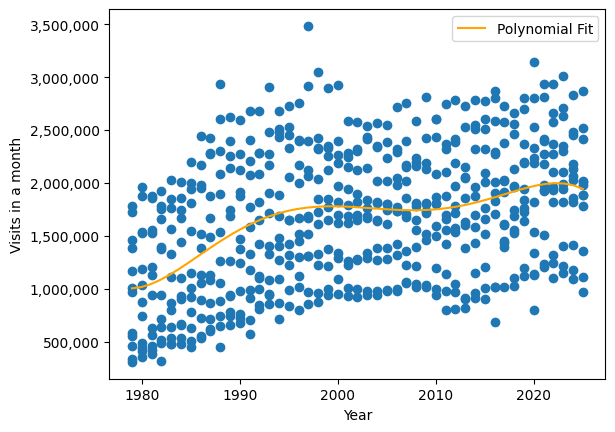

In [55]:
smokeyMountains = modern_data.query('ParkName == "Great Smoky Mountains"')
columnsToSum = ['RecreationVisits','NonRecreationVisits',	'ConcessionerLodging',
                'ConcessionerCamping',	'TentCampers','RVCampers',
                'Backcountry',	'NonRecreationOvernightStays',	'MiscellaneousOvernightStays']
smokeyMountains['Total'] = smokeyMountains[columnsToSum].sum(axis = 1)
plt.scatter(smokeyMountains['Year'],smokeyMountains['Total'])
model1 = np.poly1d(np.polyfit(smokeyMountains['Year'],smokeyMountains['Total'], deg=6))
grid1 = np.linspace(1979, 2025, 50)
plt.plot(grid1, model1(grid1), color='orange', label='Polynomial Fit')
plt.xlabel('Year')
plt.ylabel('Visits in a month')
plt.legend()
plt.gca().yaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))


In [ ]:
print(modern_data['ParkName'].unique())

['Arches' 'Badlands' 'Big Bend' 'Black Canyon of the Gunnison'
 'Bryce Canyon' 'Canyonlands' 'Capitol Reef' 'Carlsbad Caverns'
 'Chiricahua' 'Cuyahoga Valley' 'Denali' 'Gates of the Arctic'
 'Gateway Arch' 'Glacier Bay' 'Glacier' 'Grand Canyon' 'Grand Teton'
 'Great Sand Dunes' 'Guadalupe Mountains' 'Hot Springs' 'Indiana Dunes'
 'Isle Royale' 'Katmai' 'Kenai Fjords' 'Kobuk Valley' 'Lake Clark'
 'Mesa Verde' 'Petrified Forest' 'Rocky Mountain' 'Saguaro'
 'Theodore Roosevelt' 'Voyageurs' 'White Sands' 'Wind Cave'
 'Wrangell-St. Elias' 'Yellowstone' 'Zion' 'Acadia' 'Biscayne'
 'Channel Islands' 'Congaree' 'Crater Lake' 'Death Valley' 'Dry Tortugas'
 'Everglades' 'Great Basin' 'Great Smoky Mountains' 'Haleakala'
 'Hawaii Volcanoes' 'Joshua Tree' 'Kings Canyon' 'Lassen Volcanic'
 'Mammoth Cave' 'Mount Rainier' 'National Park of American Samoa'
 'New River Gorge' 'North Cascades' 'Olympic' 'Pinnacles' 'Redwood'
 'Sequoia' 'Shenandoah' 'Virgin Islands' 'Yosemite']
